# ML exploratory data analysis: tender duration (Model 1)

This notebook walks through the Phase 1 EDA behind Model 1, using **real observed data**.

**What it reads.** Only the saved outputs of the read-only Databricks extract from 2026-10-25:
- `ml/eda/extract_20261025T065554Z/`: the raw extract;
- `ml/eda/tender_labels_20261025T070133Z/`: the labels;
- `ml/eda/eda_20261025T070501Z/`: the label set with its features.

**What it does not do.** It doesn't connect to Databricks or train anything. Every number can be re-checked against
`ml/reports/ML_EDA_REPORT.md`.

**The three populations:**

| | Population | Size |
|---|---|---:|
| **L** | Valid tender-duration labels: tender first published → contract signed | 2,114 |
| **C** | Cohort contracts (`gold_contract_analytics`) | 178,921 |
| **T** | Cohort tender notices (IFB / REOI / prequalification) | 55,223 |

Models 2 and 3 have no real outcome labels, so this notebook covers only Model 1's data.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.3})


def find_ml_dir(start: Path) -> Path:
    """The ml/ folder, whether the notebook runs from ml/notebooks/, ml/ or the project root."""
    for folder in [start, *start.parents]:
        for candidate in (folder, folder / "ml"):
            if (candidate / "eda" / "eda_20261025T070501Z").is_dir():
                return candidate
    raise FileNotFoundError("Run this notebook inside the procurement-intelligence project")


def heatmap(frame: pd.DataFrame, title: str, fmt: str = "{:.0f}", cmap: str = "Blues", counts: pd.DataFrame | None = None,
            center: float | None = None, ax=None, colorbar_label: str = ""):
    """An annotated heatmap of a small table; empty rows are dropped and empty cells stay blank. counts (same shape)
    adds 'n=' under each value."""
    frame = frame.astype(float).dropna(how="all")
    counts = counts.loc[frame.index] if counts is not None else None
    ax = ax or plt.subplots(figsize=(max(6.5, 1.1 * frame.shape[1] + 3), 0.45 * frame.shape[0] + 1.6))[1]
    values = frame.values
    finite = values[np.isfinite(values)]
    if center is None:
        vmin, vmax = finite.min(), finite.max()
    else:
        spread = np.abs(finite - center).max()
        vmin, vmax = center - spread, center + spread
    image = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(frame.shape[1]), [str(c)[:30] for c in frame.columns], rotation=35, ha="right", fontsize=8)
    ax.set_yticks(range(frame.shape[0]), [str(i)[:38] for i in frame.index], fontsize=8)
    ax.grid(False)
    for (row, col), value in np.ndenumerate(values):
        if np.isnan(value):
            continue
        red, green, blue, _ = image.cmap(image.norm(value))
        dark = 0.299 * red + 0.587 * green + 0.114 * blue < 0.5
        label = fmt.format(value) + (f"\nn={int(counts.iat[row, col])}" if counts is not None else "")
        ax.text(col, row, label, ha="center", va="center", fontsize=7.5, color="white" if dark else "black")
    plt.colorbar(image, ax=ax, fraction=0.04, pad=0.02, label=colorbar_label)
    ax.set_title(title)
    return ax


ML = find_ml_dir(Path.cwd())
print("ML folder:", ML)

EXTRACT = ML / "eda" / "extract_20261025T065554Z"
LABEL_RUN = ML / "eda" / "tender_labels_20261025T070133Z"
EDA_RUN = ML / "eda" / "eda_20261025T070501Z"

labels = pd.read_parquet(EDA_RUN / "tender_label_features_eda.parquet")
manifest = json.loads((EXTRACT / "extract_manifest.json").read_text())
funnel = json.loads((LABEL_RUN / "tender_label_funnel.json").read_text())
print(f"Population L: {len(labels):,} labels x {labels.shape[1]} columns, all valid: {labels.is_valid.all()}")

ML folder: /Users/lalith/Documents/my_projects/Procurement AI Assitant Platform/procurement-intelligence/ml
Population L: 2,114 labels x 48 columns, all valid: True


## 1. Where the data came from

The extract was a read-only pull of the Gold and Silver tables. The Delta table versions were recorded **before and
after** the pull. They're identical, so nothing changed underneath the analysis.

In [2]:
pd.DataFrame({"rows": manifest["rows"]}).style.format("{:,}")

,rows
gold_contract_analytics,"178,921"
gold_procurement_notices,"243,533"
gold_project_portfolio,"2,000"
gold_country_context,"5,642"
silver_projects,"2,000"
contract_keys,"178,921"
notice_details_keys,"20,305"
ds00979_rebid_flags,"243,533"
link_candidates,"57,247"
verified_links,"12,039"


In [3]:
print("Delta versions unchanged during the extract:", manifest["unchanged"])
print("Cohort manifest SHA-256:", manifest["cohort_manifest_sha256"][:16], "...")

Delta versions unchanged during the extract: True
Cohort manifest SHA-256: 82a43185f427b3e6 ...


## 2. Building the labels: the linking funnel

A label needs a tender notice **and** the contract it led to. They're linked on the same project **and** the same
normalised procurement reference.

DS00979, the notice dataset that covers all 2,000 projects, has **no reference number**. Only the procnotices API
does, and only for 184 projects. That one gap decides how many labels exist.

,step,contracts,pct_of_cohort
0,"cohort contracts (DS00005, Gold #2)",178921,100.00
1,in the 184 projects with notice references (pr...,15177,8.48
2,with a borrower contract reference,15177,8.48
3,linked to >=1 tender notice (same project + no...,2495,1.39
4,valid after the documented rule,2114,1.18


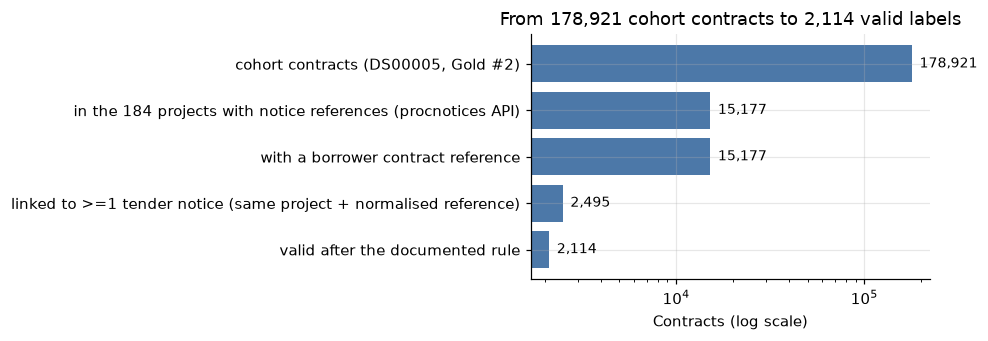

In [4]:
steps = pd.DataFrame(funnel["funnel"])[["step", "contracts", "pct_of_cohort"]]
display(steps)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(steps["step"][::-1], steps["contracts"][::-1], color="#4C78A8")
ax.set_xscale("log")
ax.set_xlabel("Contracts (log scale)")
ax.set_title("From 178,921 cohort contracts to 2,114 valid labels")
for y, value in enumerate(steps["contracts"][::-1]):
    ax.text(value * 1.1, y, f"{value:,}", va="center", fontsize=9)
plt.tight_layout()

In [5]:
pd.Series(funnel["exclusions"], name="contracts").to_frame()

,contracts
valid,2114
tender_not_before_signing,265
deadline_not_after_publication,110
no_submission_deadline,6


The documented rule removed **381** linked contracts:
- **265** back-filled notices: the tender was published on or after the signing date;
- **110** with a deadline that isn't after publication;
- **6** with no deadline at all.

## 3. The target: days from tender publication to signing

count    2114.0
mean      196.8
std       159.9
min         1.0
10%        62.0
25%        92.0
50%       144.0
75%       251.0
90%       403.0
99%       810.3
max      1372.0

Skew: raw 2.11  |  log -0.62


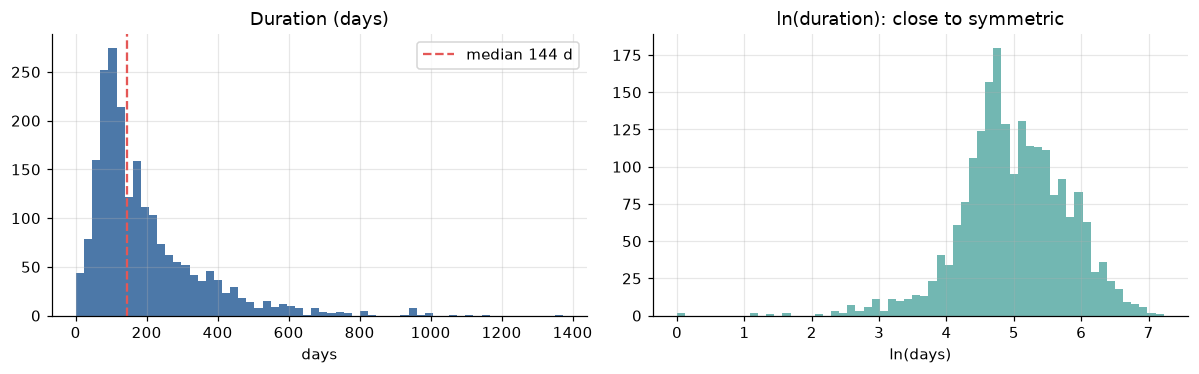

In [6]:
duration = labels["duration_days"]
print(duration.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).round(1).to_string())
print(f"\nSkew: raw {duration.skew():.2f}  |  log {np.log(duration).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(duration, bins=60, color="#4C78A8")
axes[0].axvline(duration.median(), color="#E45756", ls="--", label=f"median {duration.median():.0f} d")
axes[0].set(title="Duration (days)", xlabel="days")
axes[0].legend()
axes[1].hist(np.log(duration), bins=60, color="#72B7B2")
axes[1].set(title="ln(duration): close to symmetric", xlabel="ln(days)")
plt.tight_layout()

**Decision:** model **ln(days)**. The raw durations are right-skewed (2.11); on the log scale the skew is −0.62.
Long tenders stay in the data. They're not trimmed as outliers.

### Every advertised package, not only the labelled ones (Kaplan–Meier)

The labels only include tenders that reached a signed contract. The Kaplan–Meier curve covers **all** advertised
packages in the 184 linkable projects. It shows the share that is still unsigned after a given number of days.
Packages that never sign are counted as censored rather than dropped.

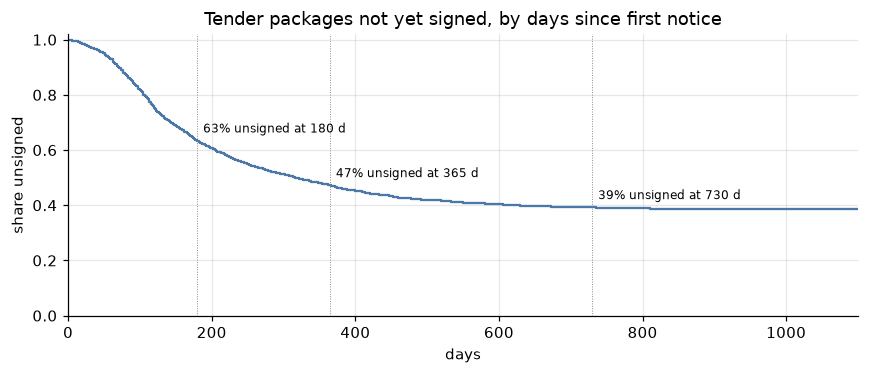

In [7]:
km = pd.read_csv(LABEL_RUN / "km_tender_package_to_first_signing.csv")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.step(km["days"], km["survival"], where="post", color="#4C78A8")
for day in (180, 365, 730):
    still_open = km.loc[km["days"] <= day, "survival"].iloc[-1]
    ax.axvline(day, color="grey", lw=0.6, ls=":")
    ax.text(day + 8, still_open + 0.03, f"{still_open:.0%} unsigned at {day} d", fontsize=8)
ax.set(title="Tender packages not yet signed, by days since first notice", xlabel="days", ylabel="share unsigned",
       ylim=(0, 1.02), xlim=(0, 1100))
plt.tight_layout()

About 39% of packages have no linked signing even after two years. They were cancelled, re-tendered, or signed under
a reference we can't match. That's why the model's estimates are *conditional on the tender being signed*.

## 4. Numeric features

In [8]:
NUMERIC = ["api_window_days", "project_age_days_at_tender", "project_prior_tender_notices",
           "gdp_growth_annual_pct", "inflation_consumer_prices_annual_pct", "wgi_control_of_corruption_est",
           "wgi_government_effectiveness_est", "cpia_irai_overall"]


def numeric_profile(frame: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    rows = {}
    for column in columns:
        values = frame[column]
        rows[column] = {"median": values.median(), "p25": values.quantile(0.25), "p75": values.quantile(0.75),
                        "skew": values.skew(), "missing_%": 100 * values.isna().mean()}
    return pd.DataFrame(rows).T.round(2)


numeric_profile(labels, NUMERIC)

,median,p25,p75,skew,missing_%
api_window_days,19.00,14.00,29.00,13.59,0.00
project_age_days_at_tender,906.00,483.00,1432.00,1.05,0.00
project_prior_tender_notices,19.00,7.00,36.00,1.75,0.00
gdp_growth_annual_pct,3.49,1.98,5.78,-0.50,5.30
inflation_consumer_prices_annual_pct,5.87,3.02,9.88,8.51,5.53
wgi_control_of_corruption_est,-0.82,-1.05,-0.44,0.87,4.87
wgi_government_effectiveness_est,-0.60,-0.85,-0.31,0.24,4.87
cpia_irai_overall,3.19,3.12,3.45,-0.41,26.40


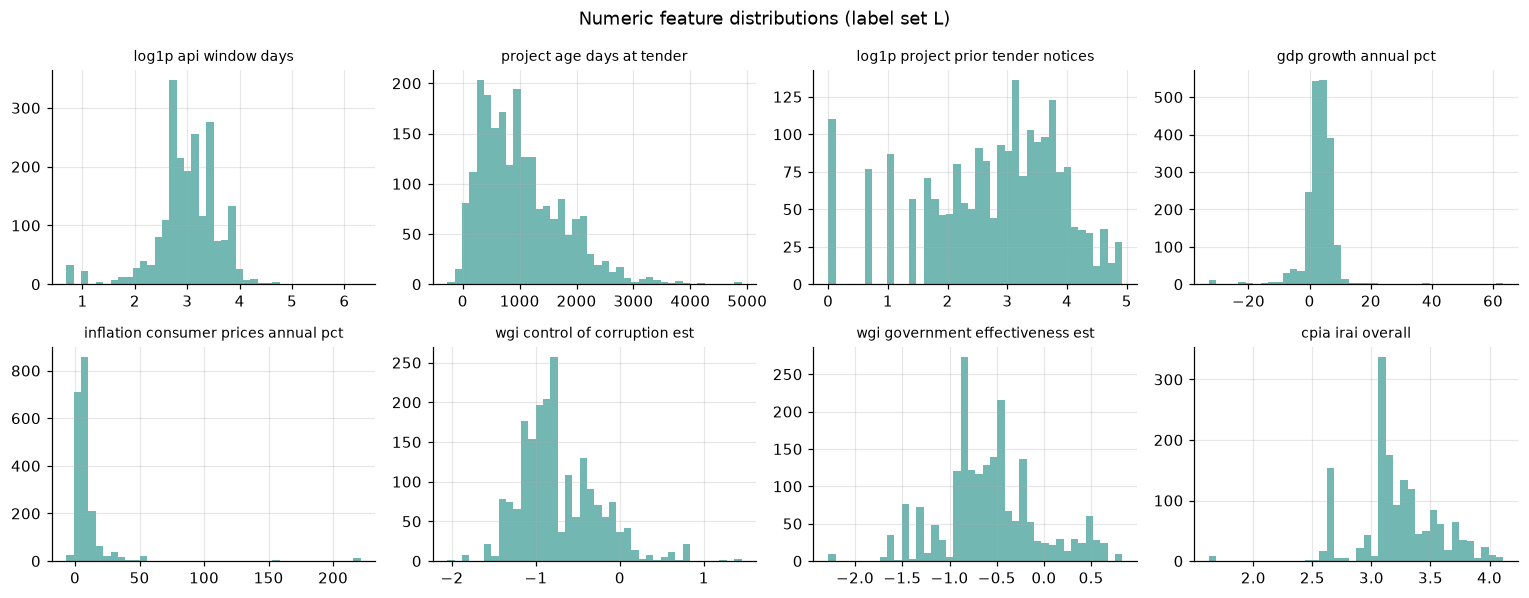

In [9]:
LOG_SCALED = {"api_window_days", "project_prior_tender_notices"}
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
for ax, column in zip(axes.flat, NUMERIC):
    values = labels[column].dropna()
    if column in LOG_SCALED:
        values = np.log1p(values)
    ax.hist(values, bins=40, color="#72B7B2")
    ax.set_title(("log1p " if column in LOG_SCALED else "") + column.replace("_", " "), fontsize=9)
plt.suptitle("Numeric feature distributions (label set L)")
plt.tight_layout()

- **Heavily skewed counts and windows:** the bid window (skew 13.6, maximum 549 days) and the count of prior notices
  are log1p-transformed in the model.
- **Missing values, flagged and never filled with zero:** CPIA is missing for 26% of labels. The country indicators
  are missing for regional projects.

## 5. Categorical features

In [10]:
for column in ["procurement_method", "procurement_category", "review_type", "first_tender_type"]:
    print(labels[column].value_counts(dropna=False).to_string(), "\n")
print("Countries:", labels["project_country_name"].nunique(), "| primary sectors:", labels["primary_major_sector"].nunique())

procurement_method
Request for Bids                       756
Individual Consultant Selection        665
Quality And Cost-Based Selection       290
Consultant Qualification  Selection    255
Request for Quotations                 102
Least Cost Selection                    20
Request for Proposals                   10
Quality Based Selection                  9
Fixed Budget Selection                   5
E-Auctions                               2 

procurement_category
Consultant Services        1244
Goods                       460
Works                       314
Non-consulting Services      96 

review_type
Post     1743
Prior     367
None        4 

first_tender_type
Request for Expression of Interest    1244
Invitation for Bids                    863
Invitation for Prequalification          7 

Countries: 79 | primary sectors: 18


- **Rare methods** (QBS, E-Auctions, RFP, FBS) have fewer than 20 labels each, so the model groups them as
  "infrequent".
- **REOI and consulting overlap:** an REOI is, by construction, a consulting tender, so `first_tender_type` adds
  little beyond `procurement_category`.

## 6. What drives duration? Group medians and Kruskal–Wallis tests

A Kruskal–Wallis test asks whether the duration distributions differ between groups. It's rank-based, so it's robust
to the skew. These are **associations, not causes**.

In [11]:
from scipy import stats


def by_group(frame: pd.DataFrame, column: str, min_n: int = 20) -> tuple[pd.DataFrame, float]:
    """Median days and count per group (groups with at least min_n labels), plus the Kruskal–Wallis p-value."""
    groups = frame.groupby(column)["duration_days"]
    table = groups.agg(median_days="median", n="size").query("n >= @min_n").sort_values("median_days")
    samples = [frame.loc[frame[column] == g, "duration_days"] for g in table.index]
    return table, stats.kruskal(*samples).pvalue


results = {}
for column in ["procurement_method", "review_type", "procurement_category", "region_name"]:
    table, p_value = by_group(labels, column)
    results[column] = p_value
    print(f"--- {column}  (Kruskal–Wallis p = {p_value:.1e})")
    print(table.to_string(), "\n")

--- procurement_method  (Kruskal–Wallis p = 1.5e-116)
                                     median_days    n
procurement_method                                   
Request for Quotations                      72.0  102
Consultant Qualification  Selection        110.0  255
Individual Consultant Selection            125.0  665
Request for Bids                           137.5  756
Least Cost Selection                       215.5   20
Quality And Cost-Based Selection           375.0  290 

--- review_type  (Kruskal–Wallis p = 4.5e-93)
             median_days     n
review_type                   
Post               123.0  1743
Prior              324.0   367 

--- procurement_category  (Kruskal–Wallis p = 6.4e-12)
                         median_days     n
procurement_category                      
Non-consulting Services         81.0    96
Goods                          130.0   460
Works                          134.0   314
Consultant Services            160.5  1244 

--- region_name  (Kruskal

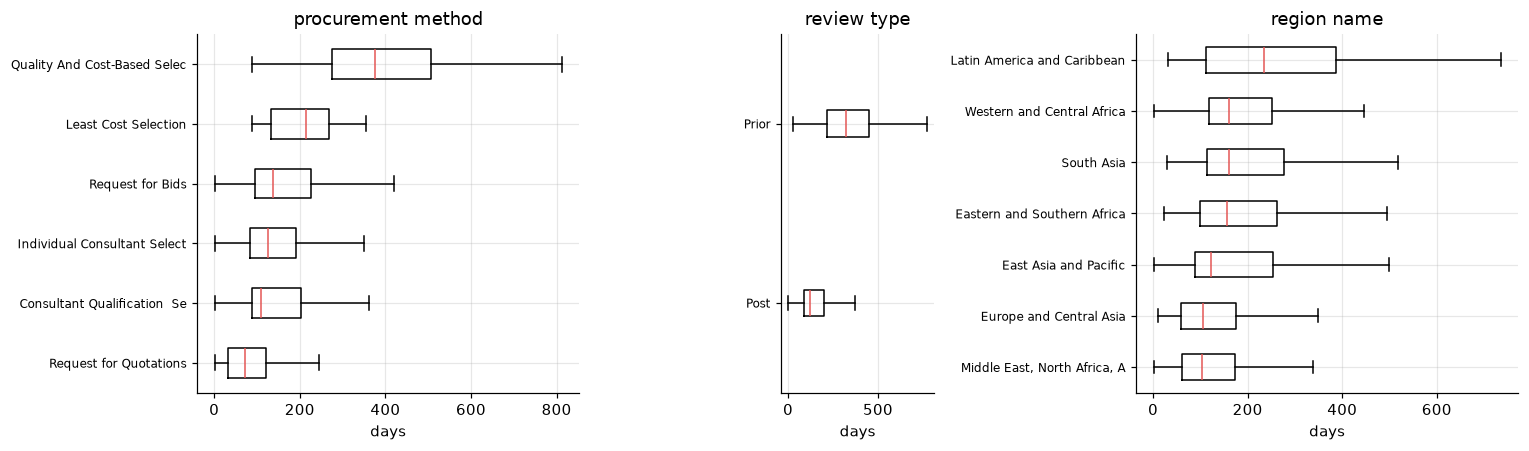

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [3, 1.2, 3]})
for ax, column in zip(axes, ["procurement_method", "review_type", "region_name"]):
    table, _ = by_group(labels, column)
    data = [labels.loc[labels[column] == g, "duration_days"] for g in table.index]
    ax.boxplot(data, orientation="horizontal", showfliers=False, medianprops={"color": "#E45756"})
    ax.set_yticks(range(1, len(table) + 1), [str(g)[:28] for g in table.index], fontsize=8)
    ax.set_title(column.replace("_", " "))
    ax.set_xlabel("days")
plt.tight_layout()

**Method and review type dominate:**
- QCBS takes a median of **375 days**, against **72** for RFQ.
- Prior review takes **324 days**, against **123** for post review.
- LAC is the slowest region (235 days).

So a simple median for each method × category is a strong baseline. Any model has to beat it (see the training
notebook).

### Heatmaps: how the factors combine

Each cell shows the **median days** for a pair of factors, with the number of labels underneath. Cells with fewer
than 10 labels are left blank, so that no conclusion rests on a handful of tenders.

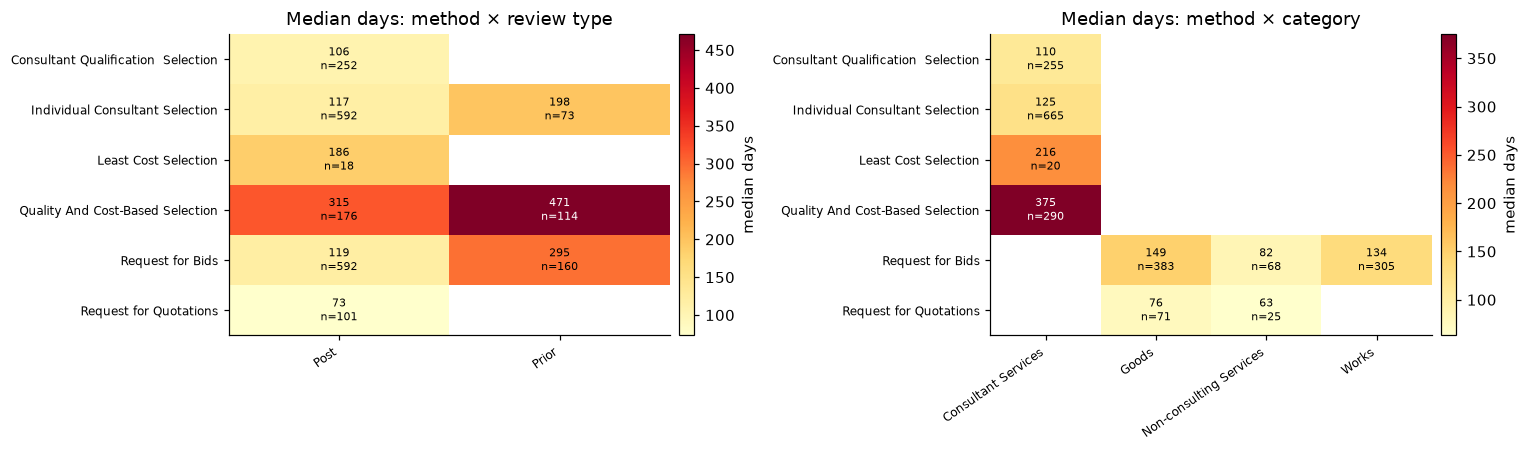

In [13]:
MAIN_METHODS = labels["procurement_method"].value_counts().loc[lambda s: s >= 20].index


def median_grid(rows: str, cols: str, min_n: int = 10) -> tuple[pd.DataFrame, pd.DataFrame]:
    subset = labels[labels["procurement_method"].isin(MAIN_METHODS)]
    medians = subset.pivot_table(index=rows, columns=cols, values="duration_days", aggfunc="median")
    counts = subset.pivot_table(index=rows, columns=cols, values="duration_days", aggfunc="size").reindex_like(medians)
    return medians.where(counts >= min_n), counts.fillna(0)


fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (cols, title) in zip(axes, (("review_type", "Median days: method × review type"),
                                    ("procurement_category", "Median days: method × category"))):
    medians, counts = median_grid("procurement_method", cols)
    heatmap(medians, title, counts=counts, cmap="YlOrRd", ax=ax, colorbar_label="median days")
plt.tight_layout()

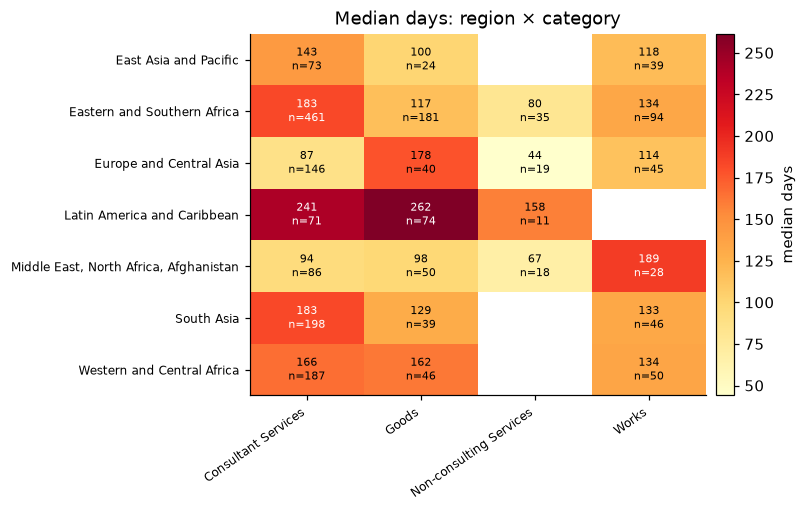

In [14]:
medians, counts = median_grid("region_name", "procurement_category")
heatmap(medians, "Median days: region × category", counts=counts, cmap="YlOrRd", colorbar_label="median days")
plt.tight_layout()

- **Prior review adds time within every method where both review types occur:**
  - Request for Bids: 119 → 295 days;
  - QCBS: 315 → 471;
  - individual consultants: 117 → 198.

  So review type isn't just a proxy for method, and the model includes both.
- **Method and category almost determine each other.** Consulting methods go with consultant services; RFB and RFQ
  go with goods, works and non-consulting services. Most of the method × category grid is therefore empty by
  construction.
- **LAC is the slowest region for consulting and goods** (about 240–260 days). In MENA, works stand out (189 days).
  Region still matters once category is fixed.

### Bid window and project age against duration

Points are individual tenders. The line shows the median duration within deciles of the feature.

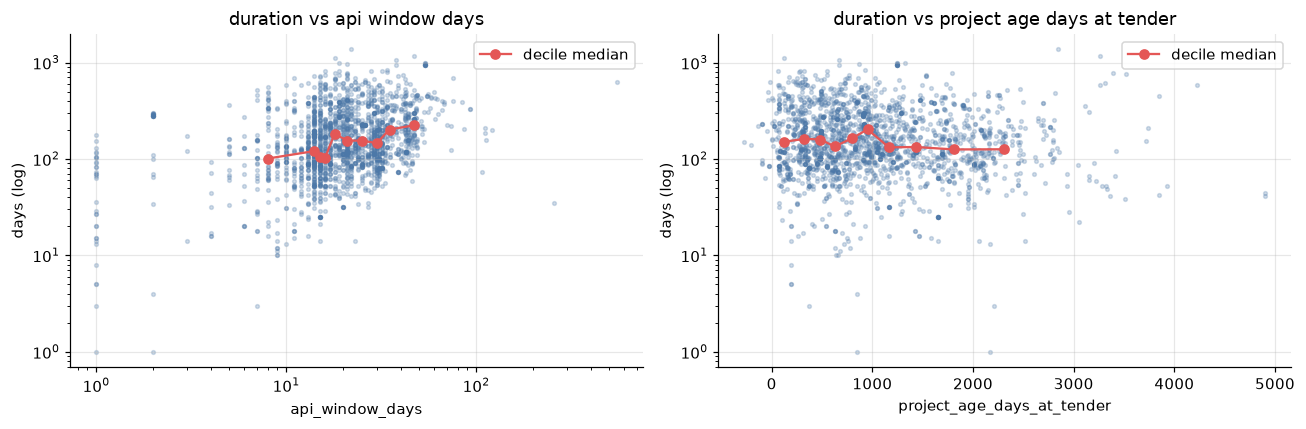

In [15]:
def binned_medians(feature: str, bins: int = 10) -> pd.DataFrame:
    frame = labels[[feature, "duration_days"]].dropna()
    frame["bin"] = pd.qcut(frame[feature], bins, duplicates="drop")
    return frame.groupby("bin", observed=True).agg(x=(feature, "median"), y=("duration_days", "median"))


fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, feature, log_x in ((axes[0], "api_window_days", True), (axes[1], "project_age_days_at_tender", False)):
    frame = labels[labels[feature] > 0] if log_x else labels
    ax.scatter(frame[feature], frame["duration_days"], s=6, alpha=0.25, color="#4C78A8")
    trend = binned_medians(feature)
    ax.plot(trend["x"], trend["y"], color="#E45756", marker="o", label="decile median")
    ax.set_yscale("log")
    if log_x:
        ax.set_xscale("log")
    ax.set(title=f"duration vs {feature.replace('_', ' ')}", xlabel=feature, ylabel="days (log)")
    ax.legend()
plt.tight_layout()

- **Longer published bid windows go with longer tenders:** the median rises from about 100 to about 220 days across
  the deciles. A likely reason is that complex tenders get longer windows, so the window partly measures complexity.
- **Project age is nearly flat on its own** (ρ −0.07). Its small negative effect only shows up in the model, once
  method and review type are held fixed.

## 7. Numeric relationships: Spearman correlation with ln(duration)

The correlations are recomputed here and checked against the saved Phase 1 values.

Matches the saved Phase 1 values: True


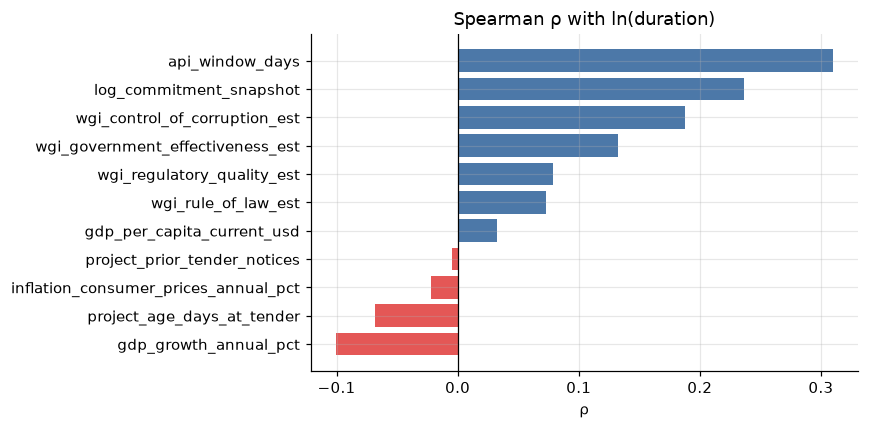

In [16]:
CANDIDATES = ["api_window_days", "log_commitment_snapshot", "wgi_control_of_corruption_est",
              "wgi_government_effectiveness_est", "wgi_rule_of_law_est", "wgi_regulatory_quality_est",
              "gdp_growth_annual_pct", "project_age_days_at_tender", "project_prior_tender_notices",
              "inflation_consumer_prices_annual_pct", "gdp_per_capita_current_usd"]
rho = labels[["log_duration", *CANDIDATES]].corr(method="spearman")["log_duration"].drop("log_duration")
saved = pd.read_csv(EDA_RUN / "spearman_correlations_L.csv", index_col=0)["log_duration"].reindex(rho.index)
print("Matches the saved Phase 1 values:", np.allclose(rho.round(3), saved, atol=0.002, equal_nan=True))

rho = rho.sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(rho.index, rho.values, color=["#E45756" if v < 0 else "#4C78A8" for v in rho.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Spearman ρ with ln(duration)", xlabel="ρ")
plt.tight_layout()

- **The published bid window is the strongest numeric signal** (ρ 0.31). It's known at tender publication, which is
  one reason publication was chosen as the prediction moment.
- **`log_commitment_snapshot` looks useful (ρ 0.24), but it's a snapshot.** Its value is *current*, not as of the
  tender date, so it would leak information. It's excluded.
- **Governance and macro indicators are weak** (|ρ| ≤ 0.19).

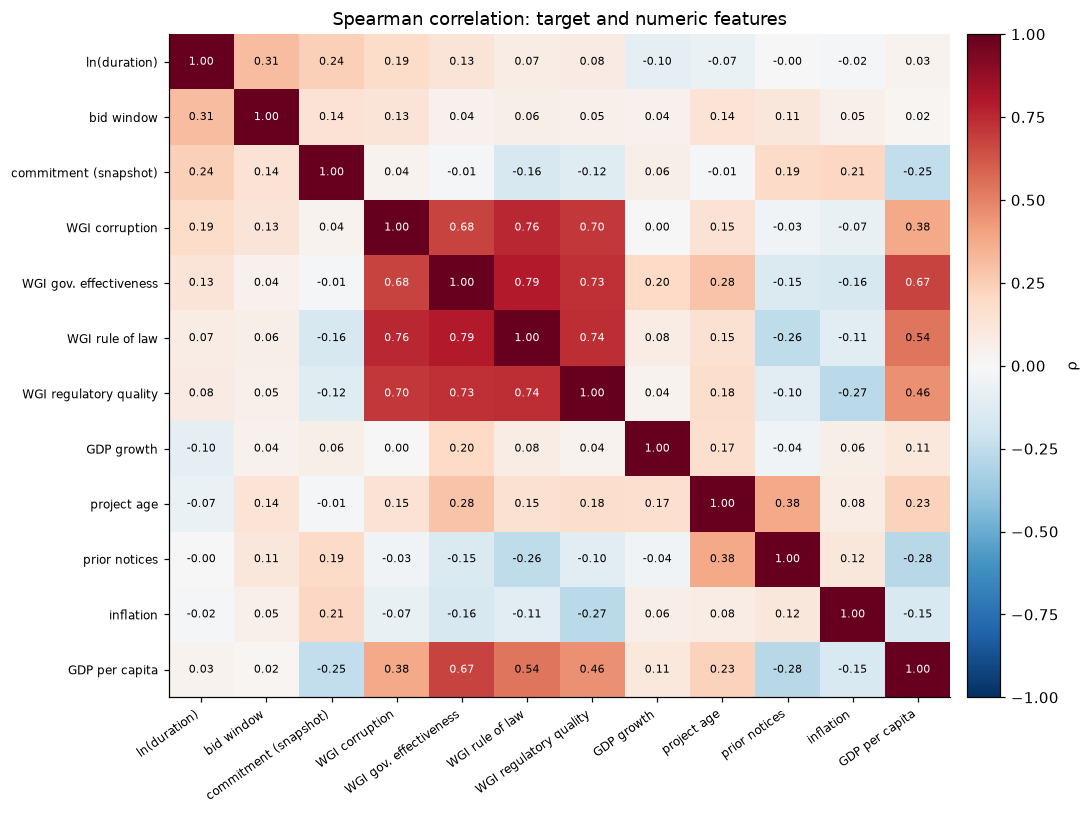

In [17]:
SHORT = {"log_duration": "ln(duration)", "api_window_days": "bid window", "log_commitment_snapshot": "commitment (snapshot)",
         "wgi_control_of_corruption_est": "WGI corruption", "wgi_government_effectiveness_est": "WGI gov. effectiveness",
         "wgi_rule_of_law_est": "WGI rule of law", "wgi_regulatory_quality_est": "WGI regulatory quality",
         "gdp_growth_annual_pct": "GDP growth", "project_age_days_at_tender": "project age",
         "project_prior_tender_notices": "prior notices", "inflation_consumer_prices_annual_pct": "inflation",
         "gdp_per_capita_current_usd": "GDP per capita"}
matrix = labels[list(SHORT)].corr(method="spearman").rename(index=SHORT, columns=SHORT)
heatmap(matrix, "Spearman correlation: target and numeric features", fmt="{:.2f}", cmap="RdBu_r", center=0,
        ax=plt.subplots(figsize=(10, 7.5))[1], colorbar_label="ρ")
plt.tight_layout()

Read the heatmap along the top row for each feature's link to the target. The dark block in the middle is the four
WGI indicators correlating with one another, which section 8 quantifies.

## 8. Multicollinearity

The variance inflation factor (VIF) is the diagonal of the inverse of the correlation matrix.

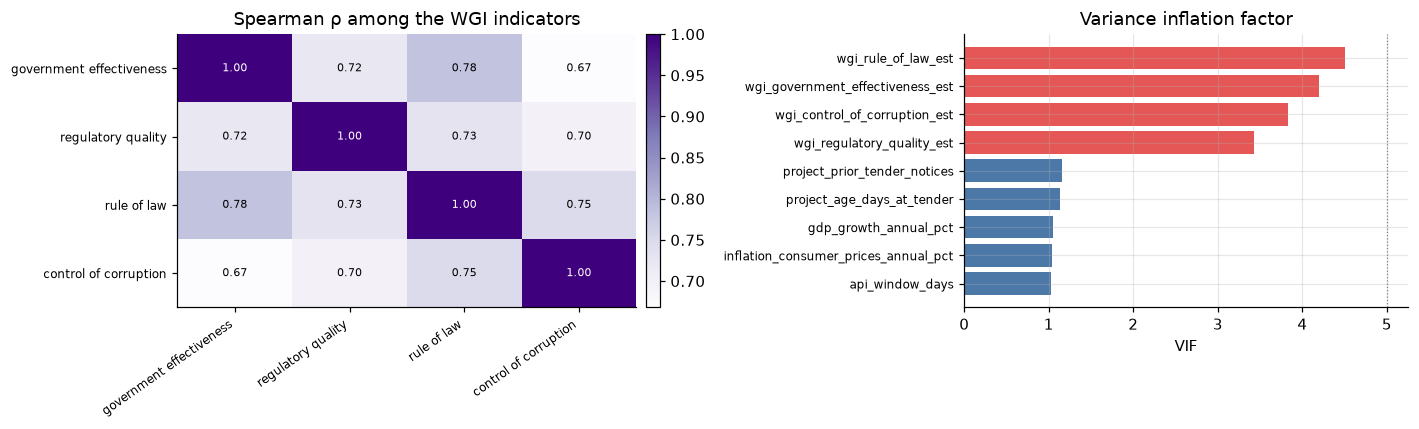

In [18]:
WGI = ["wgi_government_effectiveness_est", "wgi_regulatory_quality_est", "wgi_rule_of_law_est",
       "wgi_control_of_corruption_est"]
OTHERS = ["api_window_days", "project_age_days_at_tender", "project_prior_tender_notices",
          "gdp_growth_annual_pct", "inflation_consumer_prices_annual_pct"]
complete = labels[WGI + OTHERS].dropna()
vif = pd.Series(np.diag(np.linalg.inv(complete.corr().values)), index=complete.columns, name="VIF").sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.1, 1]})
wgi = complete[WGI].corr(method="spearman")
wgi.index = wgi.columns = [c.replace("wgi_", "").replace("_est", "").replace("_", " ") for c in WGI]
heatmap(wgi, "Spearman ρ among the WGI indicators", fmt="{:.2f}", cmap="Purples", ax=axes[0])
axes[1].barh(vif.index, vif.values, color=["#E45756" if v > 2.5 else "#4C78A8" for v in vif.values])
axes[1].axvline(5, color="grey", ls=":", lw=0.8)
axes[1].set(title="Variance inflation factor", xlabel="VIF")
axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()

The four WGI indicators move together (ρ about 0.7–0.8), with VIF up to about 5. Everything else is below 2.

Together with their weak signal and current vintage, this is why the governance indicators were kept out of the main
model. They were tried only in sensitivity runs.

## 9. Bias and data-quality checks

In [19]:
coverage = pd.read_csv(LABEL_RUN / "coverage_by_procurement_method_vs_cohort.csv")
display(coverage.sort_values("contracts", ascending=False).head(10))

top10 = labels["project_id"].value_counts().head(10).sum() / len(labels)
print(f"Top 10 projects hold {top10:.1%} of labels; median labels per project = "
      f"{labels['project_id'].value_counts().median():.0f}")

,procurement_method,contracts,valid_labels,coverage_pct
0,Request for Quotations,66201,102,0.15
1,Individual Consultant Selection,42666,665,1.56
2,Request for Bids,32313,756,2.34
3,Direct Selection,21349,0,0.00
4,Consultant Qualification Selection,8903,255,2.86
5,Quality And Cost-Based Selection,5073,290,5.72
6,Least Cost Selection,923,20,2.17
7,Community Driven Development,399,0,0.00
8,Quality Based Selection,285,9,3.16
9,Request for Proposals,243,10,4.12


Top 10 projects hold 36.3% of labels; median labels per project = 7


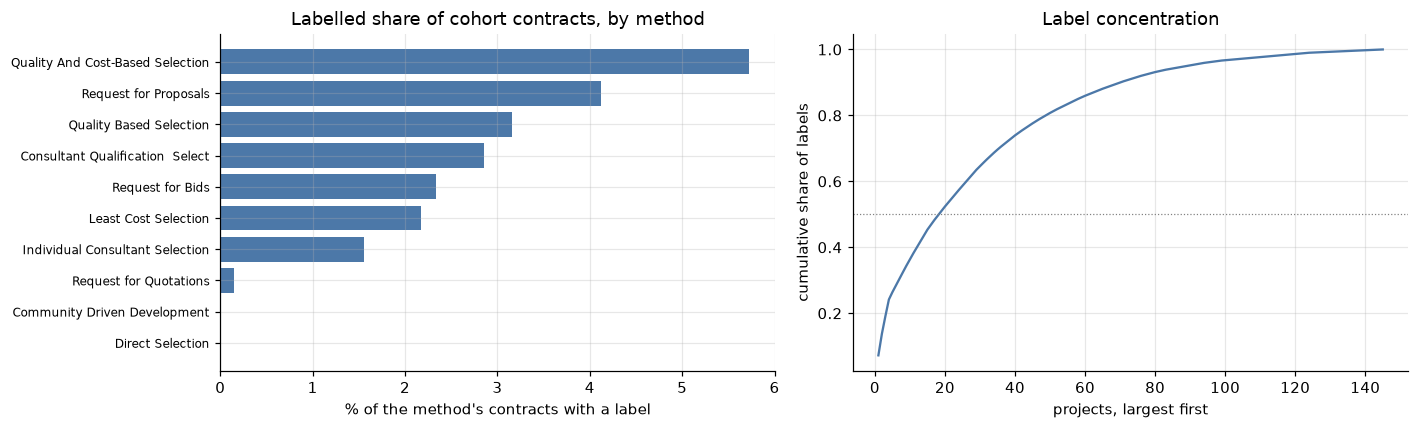

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
shown = coverage.sort_values("contracts", ascending=False).head(10).sort_values("coverage_pct")
axes[0].barh(shown["procurement_method"].str.slice(0, 32), shown["coverage_pct"], color="#4C78A8")
axes[0].set(title="Labelled share of cohort contracts, by method", xlabel="% of the method's contracts with a label")
axes[0].tick_params(axis="y", labelsize=8)

per_project = labels["project_id"].value_counts().values
axes[1].plot(np.arange(1, len(per_project) + 1), per_project.cumsum() / per_project.sum(), color="#4C78A8")
axes[1].axhline(0.5, color="grey", ls=":", lw=0.8)
axes[1].set(title="Label concentration", xlabel="projects, largest first", ylabel="cumulative share of labels")
plt.tight_layout()

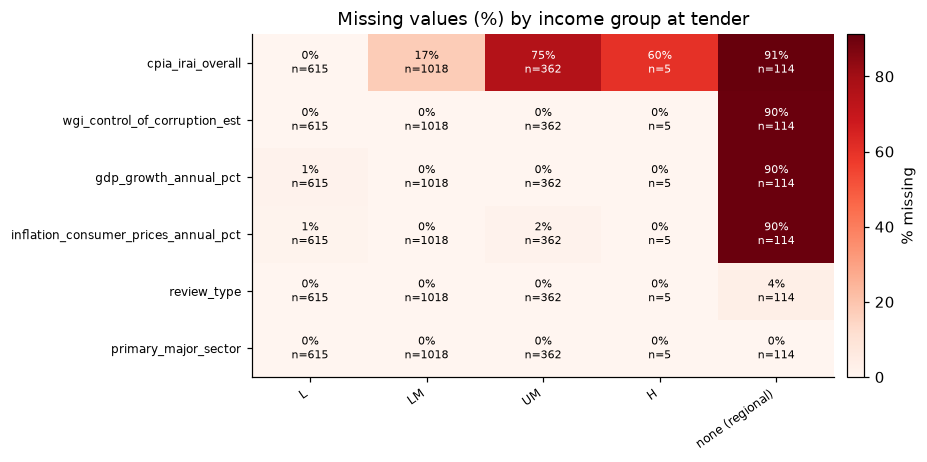

In [21]:
FEATURES_WITH_GAPS = ["cpia_irai_overall", "wgi_control_of_corruption_est", "gdp_growth_annual_pct",
                      "inflation_consumer_prices_annual_pct", "review_type", "primary_major_sector"]
income = labels["income_group_at_tender_fy"].fillna("none (regional)")
missing = (labels[FEATURES_WITH_GAPS].isna().groupby(income).mean() * 100).T
missing = missing[[c for c in ["L", "LM", "UM", "H", "none (regional)"] if c in missing.columns]]
heatmap(missing, "Missing values (%) by income group at tender", fmt="{:.0f}%", cmap="Reds",
        counts=pd.DataFrame([income.value_counts().reindex(missing.columns).values] * len(missing),
                            index=missing.index, columns=missing.columns),
        colorbar_label="% missing")
plt.tight_layout()

,median_days,n
tender_fiscal_year,,
2018,594.0,9
2019,292.0,47
2020,176.5,178
2021,166.0,211
2022,190.0,257
2023,129.0,353
2024,143.0,513
2025,124.0,310
2026,103.0,235


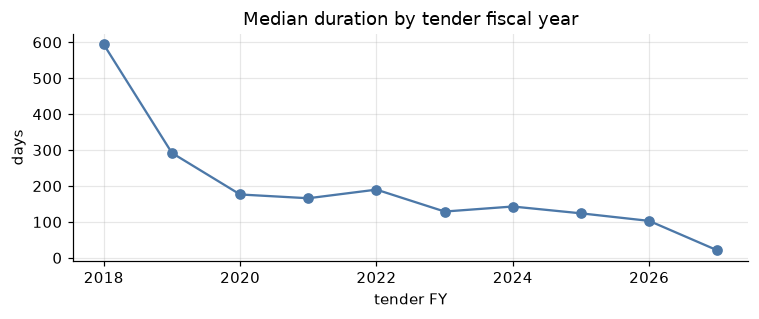

In [22]:
by_year = labels.groupby("tender_fiscal_year")["duration_days"].agg(median_days="median", n="size")
display(by_year)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_year.index, by_year["median_days"], marker="o", color="#4C78A8")
ax.set(title="Median duration by tender fiscal year", xlabel="tender FY", ylabel="days")
plt.tight_layout()

**What these checks found:**
- **Label coverage is not random.** Advertised methods are covered; RFQ barely is, and Direct Selection not at all.
  Coverage also varies by region and is concentrated in a few projects. So every metric is reported by segment, and
  results don't generalise to the whole cohort.
- **CPIA is missing not at random.** Coverage is good for low-income countries and poor for upper-middle-income
  ones. Missing values get flags; they're never treated as zero.
- **Durations are shortening.**
  - FY2026 is also **right-truncated**: only tenders already signed appear.
  - Tenders from before FY2020 are **left-truncated**.
  - So the model uses a dated split with full follow-up (see the training notebook).

## 10. Feature decisions

Every candidate feature was recorded in an inventory with its leakage risk and a decision. The table lists Model 1's
candidates.

In [23]:
inventory = pd.read_csv(ML / "eda" / "feature_inventory_20261025T070629Z" / "ML_FEATURE_INVENTORY.csv")
model1 = inventory[inventory["model"].str.startswith("M1")]
model1[["feature_name", "prediction_time_availability", "leakage_risk", "decision", "proposed_transformation"]]

,feature_name,prediction_time_availability,leakage_risk,decision,proposed_transformation
0,procurement_method,Known at planning (package method in the plan),Low,include,Group methods with <20 labels into 'Other'
1,procurement_category,Known at planning,Low,include,-
2,review_type,Known at planning (set from estimated value th...,Low; partly a proxy for estimated value,include,Missing -> 'Unknown'
3,first_tender_notice_type,Known at publication,Low,include,Prequalification (n=7) -> merge with IFB or drop
4,published_bid_window_days,Known at publication only (not at planning),Low at publication stage; must be dropped for ...,include,"log1p; cap review >180 d (flag, do not delete)"
5,region,Known (project attribute),Low,include,-
6,country,Known,"Medium: few projects per country, risk of memo...",include,Regional projects -> 'REGIONAL'; countries wit...
7,primary_major_sector,Known at approval,Low,include,Strip 'FY17 - ' prefix before grouping (taxono...
8,project_age_days_at_tender,Known,Low,include,Keep negatives; spline/bins for linear models
9,project_approval_fiscal_year,Known,Low,include,-


## Key findings

1. **There are 2,114 valid real labels**, from only 184 linkable projects. The missing reference number in DS00979
   is the biggest data gap.
2. **Method and review type dominate duration.** A segmented median baseline is hard to beat.
3. **The published bid window is the strongest numeric signal,** which supports tender publication as the
   prediction moment.
4. **Governance and macro indicators add little.** They're collinear and current-vintage, so they're used only in
   sensitivity runs.
5. **The label set is non-random** by method, region and project. The model's scope is advertised methods, and
   metrics are reported by segment.

Next: **`ML_Training.ipynb`**, covering the split, the baselines, the model comparison and the frozen model.